Name: Kriti Bhattacharya
Github: Kritiin5
USC ID: 3277100685

1a.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv('../data/Frogs_MFCCs.csv')

feature_columns = [column for column in data.columns if column.startswith('MFCC')]
label_columns = ['Family', 'Genus', 'Species']

X = data[feature_columns]
y = data[label_columns]

print("Number of features:", X.shape[1])
print("Labels:", label_columns)

Number of features: 22
Labels: ['Family', 'Genus', 'Species']


In [3]:
from sklearn.model_selection import train_test_split

combined_labels = y.astype(str).agg('_'.join, axis=1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30,random_state=552, stratify=combined_labels)

print("Training observations:", X_train.shape[0])
print("Testing observations:", X_test.shape[0])

Training observations: 5036
Testing observations: 2159


1b. i.
Exact match is the percentage of observations for which all three labels are predicted correctly. It is a strict metric because one incorrect label makes the entire observation incorrect.

Hamming loss is the fraction of individual labels that are predicted incorrectly. A lower Hamming loss is better.

Hamming score is the fraction of individual labels that are predicted correctly. A higher Hamming score is better, and it is equal to 1-Hamming loss.

In [4]:
def evaluation_scores(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    exact_match = np.mean(np.all(y_true == y_pred, axis=1))
    hamming_loss = np.mean(y_true != y_pred)
    hamming_score = np.mean(y_true == y_pred)

    return exact_match, hamming_loss, hamming_score

1b. ii.
A separate SVM is trained for Family, Genus, and Species using the one versusall method. Ten fold cross validation is used to select the penalty parameter C and Gaussian kernel parameter gamma. The raw features are used because the MFCC features are already normalized.

In [5]:
from sklearn.svm import SVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=552)
parameters = {'estimator__C': [0.1, 1, 10, 100], 'estimator__gamma': [0.1, 1, 10]}

rbf_models = {}
rbf_predictions = pd.DataFrame(index=y_test.index)
rbf_results = []

In [6]:
for label in label_columns:
    model = OneVsRestClassifier(SVC(kernel='rbf'))
    search = GridSearchCV(model, parameters, cv=cv, scoring='accuracy', n_jobs=-1)
    search.fit(X_train, y_train[label])

    rbf_models[label] = search.best_estimator_
    rbf_predictions[label] = search.predict(X_test)

    rbf_results.append({
        'Label': label,
        'Best C': search.best_params_['estimator__C'],
        'Best Gamma': search.best_params_['estimator__gamma'],
        'CV Accuracy': search.best_score_,
        'Test Accuracy': search.score(X_test, y_test[label])
    })

rbf_results = pd.DataFrame(rbf_results)
rbf_results

,Label,Best C,Best Gamma,CV Accuracy,Test Accuracy
0,Family,100,1,0.991264,0.992589
1,Genus,10,1,0.989874,0.991200
2,Species,10,1,0.989277,0.991200


In [7]:
rbf_exact, rbf_loss, rbf_score = evaluation_scores(y_test[label_columns], rbf_predictions[label_columns])

print("Exact match:", rbf_exact)
print("Hamming loss:", rbf_loss)
print("Hamming score:", rbf_score)

Exact match: 0.9888837424733673
Hamming loss: 0.008337193144974525
Hamming score: 0.9916628068550255


The Gaussian SVM performed well for all three labels, with test accuracies above 99%. The exact match score was 0.9889, meaning that all three labels were predicted correctly for about 98.89% of the test observations. The Hamming loss was 0.0083, so less than 1% of the individual labels were predicted incorrectly. The Hamming score was 0.9917.

1b. iii.

In [8]:
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

l1_parameters = {'svm__C': [0.001, 0.01, 0.1, 1, 10, 100]}

l1_models = {}
l1_predictions = pd.DataFrame(index=y_test.index)
l1_results = []

for label in label_columns:
    model = Pipeline([('scaler', StandardScaler()), ('svm', LinearSVC(penalty='l1', dual=False, max_iter=50000))])
    search = GridSearchCV(model, l1_parameters, cv=cv, scoring='accuracy', n_jobs=-1)
    search.fit(X_train, y_train[label])

    l1_models[label] = search.best_estimator_
    l1_predictions[label] = search.predict(X_test)

    l1_results.append({
        'Label': label,
        'Best C': search.best_params_['svm__C'],
        'CV Accuracy': search.best_score_,
        'Test Accuracy': search.score(X_test, y_test[label])
    })

l1_results = pd.DataFrame(l1_results)
l1_results

,Label,Best C,CV Accuracy,Test Accuracy
0,Family,10,0.934074,0.942103
1,Genus,100,0.947377,0.953219
2,Species,10,0.956707,0.958777


In [9]:
l1_exact, l1_loss, l1_score = evaluation_scores(y_test[label_columns], l1_predictions[label_columns])

print("Exact match:", l1_exact)
print("Hamming loss:", l1_loss)
print("Hamming score:", l1_score)

Exact match: 0.9157017137563687
Hamming loss: 0.04863362667901806
Hamming score: 0.951366373320982


The L1 penalized SVM achieved an exact match of 0.9157 and a Hamming score of 0.9514. Its Hamming loss was 0.0486, meaning that approximately 4.86% of the individual labels were predicted incorrectly. This model performed worse than the Gaussian SVM, which had a higher exact match and lower Hamming loss.

1b. iv.

In [10]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

smote_models = {}
smote_predictions = pd.DataFrame(index=y_test.index)
smote_results = []

In [11]:
for label in label_columns:
    model = ImbPipeline([('scaler', StandardScaler()), ('smote', SMOTE(random_state=552)), ('svm', LinearSVC(penalty='l1', dual=False, max_iter=50000))])
    search = GridSearchCV(model, l1_parameters, cv=cv, scoring='accuracy', n_jobs=-1)
    search.fit(X_train, y_train[label])

    smote_models[label] = search.best_estimator_
    smote_predictions[label] = search.predict(X_test)

    smote_results.append({
        'Label': label,
        'Best C': search.best_params_['svm__C'],
        'CV Accuracy': search.best_score_,
        'Test Accuracy': search.score(X_test, y_test[label])
    })

smote_results = pd.DataFrame(smote_results)
smote_results

,Label,Best C,CV Accuracy,Test Accuracy
0,Family,10.0,0.917591,0.926355
1,Genus,1.0,0.909647,0.918481
2,Species,0.1,0.954720,0.958777


In [12]:
smote_exact, smote_loss, smote_score = evaluation_scores(y_test[label_columns], smote_predictions[label_columns])

print("Exact match:", smote_exact)
print("Hamming loss:", smote_loss)
print("Hamming score:", smote_score)

Exact match: 0.8656785548865216
Hamming loss: 0.06546240543461479
Hamming score: 0.9345375945653852


In [13]:
comparison = pd.DataFrame({
    'Model': ['Gaussian SVM', 'L1 SVM', 'L1 SVM with SMOTE'],
    'Exact Match': [rbf_exact, l1_exact, smote_exact],
    'Hamming Loss': [rbf_loss, l1_loss, smote_loss],
    'Hamming Score': [rbf_score, l1_score, smote_score]
})

comparison

,Model,Exact Match,Hamming Loss,Hamming Score
0,Gaussian SVM,0.988884,0.008337,0.991663
1,L1 SVM,0.915702,0.048634,0.951366
2,L1 SVM with SMOTE,0.865679,0.065462,0.934538


The L1 SVM with SMOTE achieved an exact match of 0.8657, a Hamming loss of 0.0655, and a Hamming score of 0.9345. Based on these metrics, SMOTE did not improve the model. The Gaussian SVM performed best overall, followed by the regular L1 SVM. The SMOTE model had the lowest exact match and highest Hamming loss.

2a.
K-means is applied to the complete dataset because this is an unsupervised learning problem. The best number of clusters is selected using the silhouette score. A higher silhouette score represents better-separated clusters.

In [14]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X_cluster = data[feature_columns]
k_values = range(2, 51)
silhouette_scores = []

for k in k_values:
    model = KMeans(n_clusters=k, n_init=10, random_state=552)
    cluster_labels = model.fit_predict(X_cluster)
    score = silhouette_score(X_cluster, cluster_labels, sample_size=1000, random_state=552)
    silhouette_scores.append(score)

best_k = list(k_values)[np.argmax(silhouette_scores)]

print("Best k:", best_k)
print("Best silhouette score:", max(silhouette_scores))

Best k: 4
Best silhouette score: 0.3766053024790896


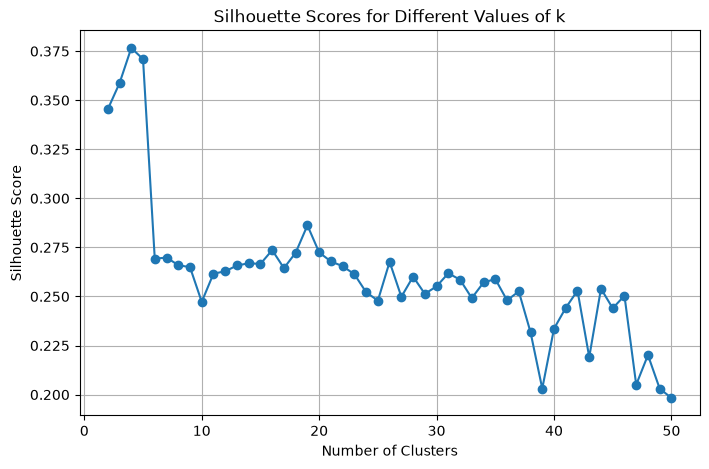

In [15]:
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), silhouette_scores, marker='o')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Scores for Different Values of k')
plt.grid()
plt.show()

The highest silhouette score was 0.3766 at k=4. Therefore, four clusters were selected for K-means clustering. The score decreases noticeably after four clusters, which supports this choice.

2b.

In [16]:
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=552)
clusters = kmeans.fit_predict(X_cluster)

clustered_data = data[label_columns].copy()
clustered_data['Cluster'] = clusters

majority_labels = []

for cluster in range(best_k):
    cluster_data = clustered_data[clustered_data['Cluster'] == cluster]

    majority_labels.append({
        'Cluster': cluster,
        'Family': cluster_data['Family'].mode()[0],
        'Genus': cluster_data['Genus'].mode()[0],
        'Species': cluster_data['Species'].mode()[0]
    })

majority_table = pd.DataFrame(majority_labels)
majority_table

,Cluster,Family,Genus,Species
0,0,Hylidae,Hypsiboas,HypsiboasCordobae
1,1,Leptodactylidae,Adenomera,AdenomeraHylaedactylus
2,2,Hylidae,Hypsiboas,HypsiboasCordobae
3,3,Leptodactylidae,Adenomera,AdenomeraAndre


Each cluster was assigned the most common Family, Genus, and Species among its observations. Clusters 0 and 2 have the same majority label triplet, while clusters 1 and 3 mainly differ in their majority Species.

2c.

In [17]:
true_labels = data[label_columns].to_numpy()

def run_kmeans(seed):
    model = KMeans(n_clusters=best_k, n_init=10, random_state=seed)
    clusters = model.fit_predict(X_cluster)
    predicted_labels = np.empty(true_labels.shape, dtype=object)

    for cluster in range(best_k):
        rows = clusters == cluster

        for j, label in enumerate(label_columns):
            majority = data.loc[rows, label].mode()[0]
            predicted_labels[rows, j] = majority

    incorrect = true_labels != predicted_labels
    hamming_distance = incorrect.sum(axis=1).mean()
    hamming_loss = incorrect.mean()
    hamming_score = 1 - hamming_loss

    return hamming_distance, hamming_score, hamming_loss

In [18]:
simulation_results = []

for run in range(50):
    distance, score, loss = run_kmeans(run)
    simulation_results.append({'Run': run + 1, 'Hamming Distance': distance, 'Hamming Score': score, 'Hamming Loss': loss})

simulation_results = pd.DataFrame(simulation_results)
simulation_results.head()

,Run,Hamming Distance,Hamming Score,Hamming Loss
0,1,0.667269,0.777577,0.222423
1,2,0.667269,0.777577,0.222423
2,3,0.735372,0.754876,0.245124
3,4,0.667269,0.777577,0.222423
4,5,0.667269,0.777577,0.222423


In [19]:
simulation_summary = simulation_results[['Hamming Distance', 'Hamming Score', 'Hamming Loss']].agg(['mean', 'std']).T
simulation_summary

,mean,std
Hamming Distance,0.671889,0.016978
Hamming Score,0.776037,0.005659
Hamming Loss,0.223963,0.005659


Across the 50 runs, the average Hamming distance was 0.6719 with a standard deviation of 0.0170. This means that approximately 0.67 of the three labels were incorrect per observation. The average Hamming score was 0.7760, while the average Hamming loss was 0.2240. The small standard deviations show that the clustering results were fairly consistent across the 50 runs.

3.

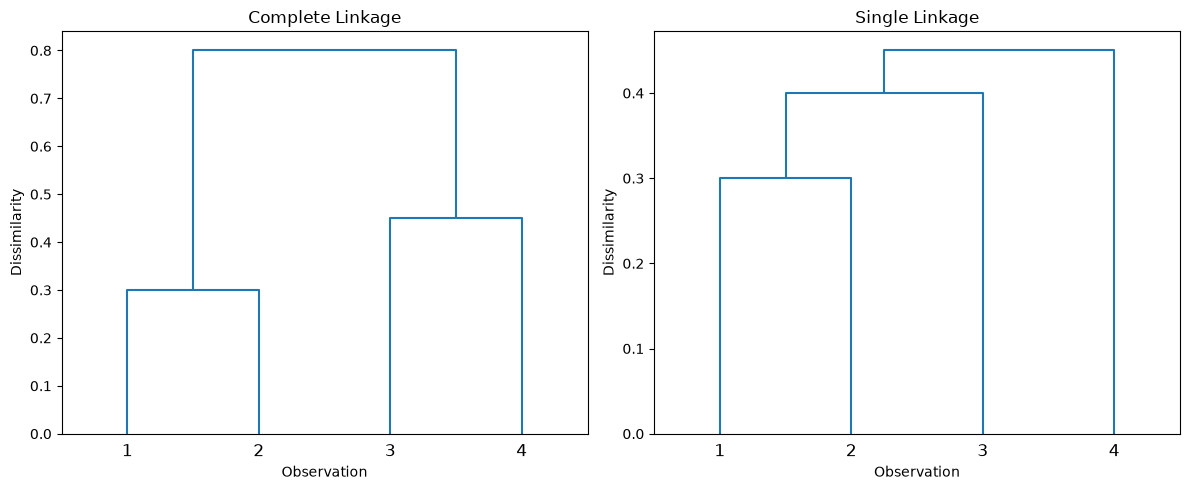

In [20]:
from scipy.cluster.hierarchy import dendrogram

complete_linkage = np.array([[0, 1, 0.30, 2], [2, 3, 0.45, 2], [4, 5, 0.80, 4]])
single_linkage = np.array([[0, 1, 0.30, 2], [4, 2, 0.40, 3], [5, 3, 0.45, 4]])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

dendrogram(complete_linkage, labels=['1', '2', '3', '4'], ax=axes[0], color_threshold=0)
axes[0].set_title('Complete Linkage')
axes[0].set_xlabel('Observation')
axes[0].set_ylabel('Dissimilarity')

dendrogram(single_linkage, labels=['1', '2', '3', '4'], ax=axes[1], color_threshold=0)
axes[1].set_title('Single Linkage')
axes[1].set_xlabel('Observation')
axes[1].set_ylabel('Dissimilarity')

plt.tight_layout()
plt.show()

a.
Observations 1 and 2 are first combined at a height of 0.30. Observations 3 and 4 are then combined at a height of 0.45. Finally, clusters {1, 2} and {3, 4} are combined at a height of 0.80 because complete linkage uses the largest dissimilarity between the clusters.


b.
Observations 1 and 2 are first combined at a height of 0.30. Observation 3 joins this cluster at a height of 0.40. Observation 4 then joins the cluster at a height of 0.45 because single linkage uses the smallest dissimilarity between clusters.

c.
Cutting the complete-linkage dendrogram to obtain two clusters gives:
Cluster 1: observations 1 and 2
Cluster 2: observations 3 and 4

d.
Cutting the single-linkage dendrogram to obtain two clusters gives:
Cluster 1: observations 1, 2, and 3
Cluster 2: observation 4

e.
The branches of a dendrogram can be flipped without changing which observations are combined or the heights of the fusions. Therefore, changing the leaf order while keeping the same merges produces an equivalent dendrogram.

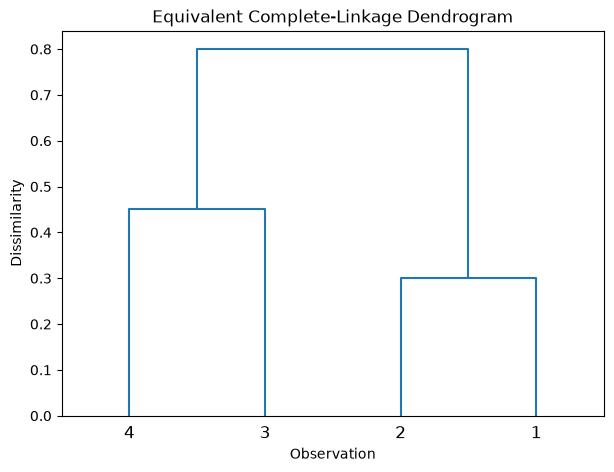

In [21]:
equivalent_linkage = np.array([[1, 0, 0.30, 2], [3, 2, 0.45, 2], [5, 4, 0.80, 4]])

plt.figure(figsize=(7, 5))
dendrogram(equivalent_linkage, labels=['1', '2', '3', '4'], color_threshold=0)
plt.title('Equivalent Complete-Linkage Dendrogram')
plt.xlabel('Observation')
plt.ylabel('Dissimilarity')
plt.show()